# Weather derivatives en Python — notebook de préparation (ENGIE WES)

Notebook de bout en bout, pensé comme une **boîte à outils** pour un test Python de 4h sur le risque météo :

| # | Partie | Ce que ça couvre |
|---|---|---|
| 0 | Setup | imports, configuration, conventions |
| 1 | Données via API | Open-Meteo, `requests`, cache, fallback, nettoyage |
| 2 | Exploration | climatologie, saisonnalité, tendance, graphes seaborn |
| 3 | Degree days | HDD / CDD / CAT, indices saisonniers, fenêtres qui chevauchent l'année |
| 4 | Modèle de température | tendance + saisonnalité + AR(p) (≈ Ornstein-Uhlenbeck discret), volatilité saisonnière, diagnostics |
| 5 | Simulation Monte Carlo | trajectoires vectorisées, validation vs historique |
| 6 | Architecture POO | `WeatherContract`, `Pricer` abstrait, Burn / Index / Monte Carlo |
| 7 | Pricing | comparaison des méthodes, chargement de risque, VaR/CVaR, convergence, sensibilités |
| 8 | Cas client | exposition volume ↔ HDD, dimensionnement de la couverture, put vs swap vs collar zero-cost |
| 9 | Suivi en cours de période | MtM conditionnel à la météo observée |
| 10 | Portefeuille multi-villes | corrélation, back-to-back avec capacity provider, risque de base |
| 11 | Tests unitaires | `assert` sur les payoffs et les indices |
| 12 | Antisèche | snippets pandas / numpy / POO / API / git + questions d'entretien |

**Convention de lecture :** chaque partie commence par un rappel théorique court, puis le code. Les fonctions sont écrites pour être **réutilisables telles quelles** le jour J.

> Si l'API n'est pas joignable, le notebook bascule automatiquement sur des données synthétiques réalistes (Paris & Lyon), donc tout tourne quand même.

## 0. Setup

In [1]:
from __future__ import annotations

import warnings
from abc import ABC, abstractmethod
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Literal, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats
from scipy.optimize import brentq
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 140)

SEED = 42
RNG = np.random.default_rng(SEED)

In [2]:
# ---------------- Configuration globale ----------------
CITIES = {                       # (latitude, longitude)
    "Paris": (48.8566, 2.3522),
    "Lyon":  (45.7640, 4.8357),
}
HIST_START, HIST_END = "1991-01-01", "2025-12-31"
VALUATION_DATE = pd.Timestamp("2026-10-14")
BASE_TEMP = 18.0                 # base Europe (°C) ; US = 65°F
RATE = 0.03                      # taux d'actualisation annuel (continu)
DATA_DIR = Path("data_weather")
DATA_DIR.mkdir(exist_ok=True)

# Période de risque type : hiver Nov–Mar et été Mai–Sep
WINTER = (pd.Timestamp("2026-11-01"), pd.Timestamp("2027-03-31"))
SUMMER = (pd.Timestamp("2027-05-01"), pd.Timestamp("2027-09-30"))

## 1. Récupération des données via API

**Open-Meteo Historical API** (gratuite, sans clé) : `https://archive-api.open-meteo.com/v1/archive`
Paramètres utiles : `latitude`, `longitude`, `start_date`, `end_date` (YYYY-MM-DD), `daily=temperature_2m_mean,temperature_2m_max,temperature_2m_min`, `timezone=Europe/Paris`.
La réponse JSON contient un bloc `daily` avec une liste `time` et une liste par variable : il suffit de `pd.DataFrame(js["daily"])`.

**Convention marché :** sur les contrats météo, la température du jour est en général **Tavg = (Tmax + Tmin) / 2**, pas la moyenne horaire. On calcule les deux et on garde la convention marché.

Bonnes pratiques à montrer : `timeout`, `raise_for_status()`, retries, cache disque (on ne rappelle pas l'API à chaque run), validation des données reçues.

In [3]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"


def fetch_open_meteo(lat: float, lon: float, start: str, end: str,
                     timeout: int = 60, retries: int = 3) -> pd.DataFrame:
    # Télécharge les températures journalières (moyenne, max, min) depuis Open-Meteo.
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": start, "end_date": end,
        "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min",
        "timezone": "Europe/Paris",
    }
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(ARCHIVE_URL, params=params, timeout=timeout)
            r.raise_for_status()
            js = r.json()
            if "daily" not in js:
                raise ValueError(f"Réponse inattendue : {list(js)[:5]}")
            df = pd.DataFrame(js["daily"])
            df["time"] = pd.to_datetime(df["time"])
            df = (df.set_index("time")
                    .rename(columns={"temperature_2m_mean": "tmean_hourly",
                                     "temperature_2m_max": "tmax",
                                     "temperature_2m_min": "tmin"}))
            df.index.name = "date"
            return df
        except Exception as err:          # réseau, HTTP, JSON...
            last_err = err
            print(f"  tentative {attempt}/{retries} échouée : {err.__class__.__name__}")
    raise ConnectionError(f"Open-Meteo injoignable : {last_err}")

In [4]:
def make_synthetic_history(start: str, end: str, seed: int = 0,
                           rho: float = 0.85) -> dict[str, pd.DataFrame]:
    # Données de secours réalistes : tendance + saisonnalité + AR(1) à vol saisonnière,
    # chocs corrélés entre Paris et Lyon. Quelques trous ajoutés pour l'exercice de nettoyage.
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, end, freq="D")
    n = len(idx)
    t_years = np.arange(n) / 365.25
    w = 2 * np.pi / 365.25
    doy = idx.dayofyear.to_numpy()
    params = {  # moyenne, réchauffement /an, amplitude, phi, vol de base
        "Paris": dict(a=11.6, b=0.035, A=7.6, phi=0.74, s=2.5),
        "Lyon":  dict(a=12.0, b=0.040, A=9.3, phi=0.72, s=2.7),
    }
    L = np.linalg.cholesky(np.array([[1, rho], [rho, 1]]))
    z = rng.standard_normal((n, 2)) @ L.T
    out = {}
    for j, (city, p) in enumerate(params.items()):
        mean = p["a"] + p["b"] * t_years - p["A"] * np.cos(w * (doy - 15))
        vol = p["s"] * (1 + 0.22 * np.cos(w * (doy - 15)))        # plus volatile en hiver
        e = np.zeros(n)
        for i in range(1, n):
            e[i] = p["phi"] * e[i - 1] + vol[i] * z[i, j]
        tavg = mean + e
        spread = 4.2 + 1.5 * np.sin(w * (doy - 100)) + rng.normal(0, 1.0, n)
        df = pd.DataFrame({"tmax": tavg + spread / 2, "tmin": tavg - spread / 2}, index=idx)
        df["tmean_hourly"] = tavg + rng.normal(0, 0.3, n)
        # trous réalistes : valeurs manquantes + lignes absentes
        nan_rows = rng.choice(n, 40, replace=False)
        df.iloc[nan_rows, 0] = np.nan
        drop_rows = rng.choice(n, 25, replace=False)
        df = df.drop(df.index[drop_rows])
        df.index.name = "date"
        out[city] = df.round(1)
    return out


def load_history(cities: dict, start: str, end: str, use_cache: bool = True):
    # Essaie le cache, puis l'API ; si une ville échoue, bascule tout en synthétique (cohérence).
    raw = {}
    try:
        for city, (lat, lon) in cities.items():
            path = DATA_DIR / f"{city}_{start}_{end}.csv"
            if use_cache and path.exists():
                raw[city] = pd.read_csv(path, index_col="date", parse_dates=True)
                print(f"{city}: chargé depuis le cache ({len(raw[city])} lignes)")
            else:
                print(f"{city}: appel API...")
                raw[city] = fetch_open_meteo(lat, lon, start, end)
                raw[city].to_csv(path)
        return raw, "Open-Meteo"
    except ConnectionError as err:
        print(f"\n>>> {err}\n>>> Bascule sur données SYNTHÉTIQUES.")
        return make_synthetic_history(start, end), "synthétique"


raw, DATA_SOURCE = load_history(CITIES, HIST_START, HIST_END)
print("\nSource :", DATA_SOURCE)
raw["Paris"].head()

Paris: appel API...


  tentative 1/3 échouée : ProxyError


  tentative 2/3 échouée : ProxyError


  tentative 3/3 échouée : ProxyError

>>> Open-Meteo injoignable : HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/archive?latitude=48.8566&longitude=2.3522&start_date=1991-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min&timezone=Europe%2FParis (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))
>>> Bascule sur données SYNTHÉTIQUES.

Source : synthétique


,tmax,tmin,tmean_hourly
date,,,
1991-01-01,6.20,2.20,4.70
1991-01-02,7.60,4.70,6.40
1991-01-03,6.20,1.70,4.40
1991-01-04,9.20,6.80,7.60
1991-01-05,6.00,3.70,4.60


### Nettoyage

Checklist systématique : dates manquantes (`reindex` sur un calendrier complet), NaN, doublons, valeurs aberrantes (sauts > 15°C d'un jour à l'autre, températures impossibles), cohérence `tmin ≤ tmax`.
On interpole **avec une limite** (on ne bouche pas 3 semaines de trou avec une droite).

In [5]:
def clean_temperatures(df: pd.DataFrame, max_gap: int = 5) -> tuple[pd.DataFrame, dict]:
    report = {}
    df = df[~df.index.duplicated(keep="first")].sort_index()
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="D", name="date")
    report["dates_absentes"] = len(full_idx) - len(df)
    df = df.reindex(full_idx)
    report["nan_avant"] = int(df[["tmax", "tmin"]].isna().sum().sum())

    # incohérences physiques -> NaN puis interpolation
    bad = (df["tmin"] > df["tmax"]) | (df["tmax"] > 48) | (df["tmin"] < -35)
    report["incoherences"] = int(bad.sum())
    df.loc[bad, ["tmax", "tmin"]] = np.nan

    df = df.interpolate(method="time", limit=max_gap)
    report["nan_apres"] = int(df[["tmax", "tmin"]].isna().sum().sum())

    df["tavg"] = (df["tmax"] + df["tmin"]) / 2          # convention marché
    jumps = df["tavg"].diff().abs()
    report["sauts_>12C"] = int((jumps > 12).sum())
    return df, report


temps, reports = {}, {}
for city, df in raw.items():
    temps[city], reports[city] = clean_temperatures(df)
pd.DataFrame(reports)

,Paris,Lyon
dates_absentes,25,25
nan_avant,90,90
incoherences,6,12
nan_apres,0,0
sauts_>12C,1,1


In [6]:
# Série principale utilisée dans la suite
T = {city: df["tavg"].dropna() for city, df in temps.items()}
paris = temps["Paris"]
paris.describe().T

,count,mean,std,min,25%,50%,75%,max
tmax,"12,784.00",14.36,7.15,-11.00,8.80,14.70,20.30,32.60
tmin,"12,784.00",10.16,6.29,-11.40,5.50,10.60,15.20,26.60
tmean_hourly,"12,784.00",12.25,6.70,-11.40,7.20,12.60,17.70,29.20
tavg,"12,784.00",12.26,6.69,-11.20,7.20,12.65,17.70,29.50


## 2. Exploration

Ce qu'on veut voir avant de modéliser :
1. la **saisonnalité** (forme et amplitude) ;
2. la **tendance** de long terme (réchauffement, effet d'îlot urbain) — essentielle car elle biaise le burn analysis non détrendé ;
3. la **volatilité saisonnière** (l'hiver est plus volatil que l'été en Europe) ;
4. l'**autocorrélation** (une vague de froid dure plusieurs jours).

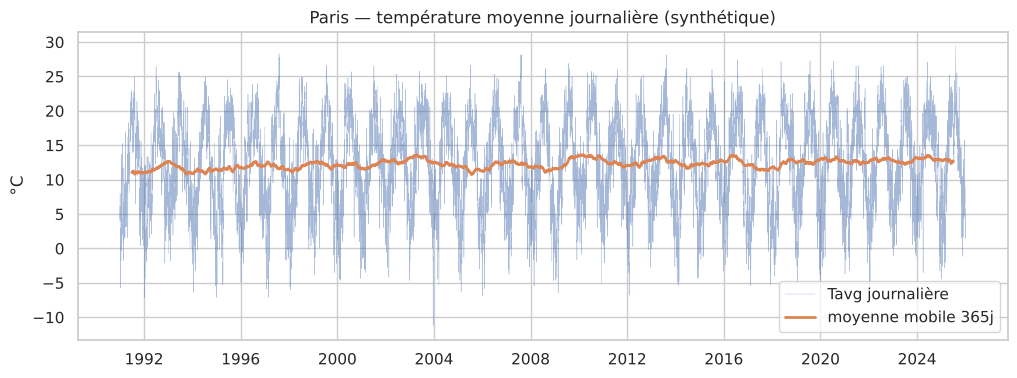

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
s = T["Paris"]
ax.plot(s.index, s, lw=0.3, alpha=0.5, label="Tavg journalière")
ax.plot(s.rolling(365, center=True).mean(), lw=2, label="moyenne mobile 365j")
ax.set(title=f"Paris — température moyenne journalière ({DATA_SOURCE})", ylabel="°C")
ax.legend(); plt.show()

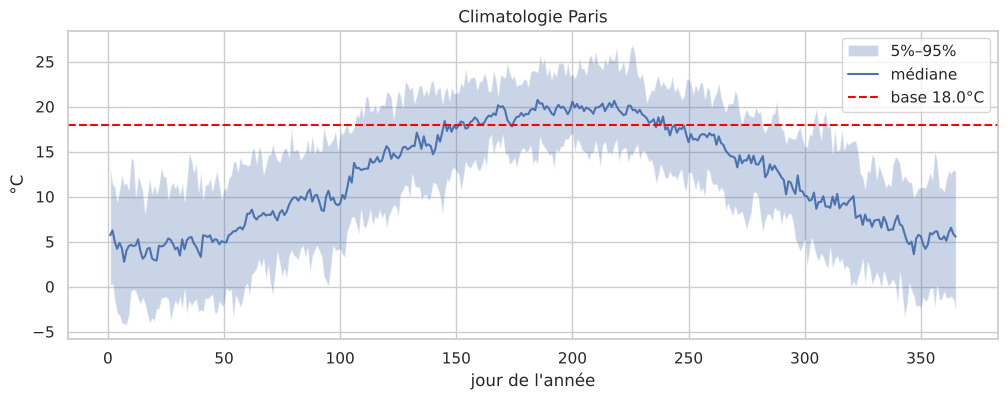

In [8]:
# Climatologie par jour de l'année : moyenne et quantiles
clim = (s.to_frame("t").assign(doy=s.index.dayofyear)
          .query("doy <= 365")
          .groupby("doy")["t"].quantile([0.05, 0.5, 0.95]).unstack())
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(clim.index, clim[0.05], clim[0.95], alpha=0.3, label="5%–95%")
ax.plot(clim.index, clim[0.5], label="médiane")
ax.axhline(BASE_TEMP, color="red", ls="--", label=f"base {BASE_TEMP}°C")
ax.set(title="Climatologie Paris", xlabel="jour de l'année", ylabel="°C"); ax.legend(); plt.show()

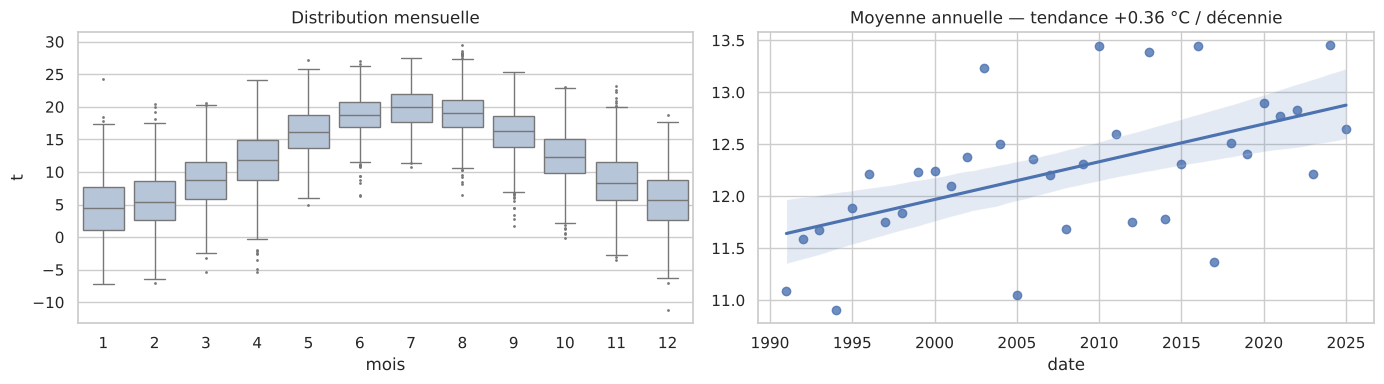

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
dfm = s.to_frame("t").assign(mois=s.index.month)
sns.boxplot(data=dfm, x="mois", y="t", ax=axes[0], color="lightsteelblue", fliersize=1)
axes[0].set_title("Distribution mensuelle")

annual = s.groupby(s.index.year).mean()
sns.regplot(x=annual.index, y=annual.values, ax=axes[1], ci=95)
slope = np.polyfit(annual.index, annual.values, 1)[0]
axes[1].set_title(f"Moyenne annuelle — tendance {slope*10:+.2f} °C / décennie")
plt.tight_layout(); plt.show()

In [10]:
# Volatilité par mois des variations journalières + corrélation inter-villes
vol_month = s.diff().groupby(s.index.month).std()
both = pd.concat(T, axis=1).dropna()
print("Écart-type des variations journalières par mois :\n", vol_month.round(2).to_dict())
print(f"\nCorrélation Paris/Lyon (niveaux) : {both.corr().iloc[0,1]:.3f}")
print(f"Corrélation Paris/Lyon (variations journalières) : {both.diff().corr().iloc[0,1]:.3f}")

Écart-type des variations journalières par mois :
 {1: 3.15, 2: 3.3, 3: 2.95, 4: 2.59, 5: 2.43, 6: 2.12, 7: 2.12, 8: 2.11, 9: 2.38, 10: 2.66, 11: 2.97, 12: 3.13}

Corrélation Paris/Lyon (niveaux) : 0.954
Corrélation Paris/Lyon (variations journalières) : 0.844


## 3. Degree days et indices saisonniers

- **HDD** (Heating Degree Day) : $HDD_t = \max(0,\ B - T_t)$ → mesure le besoin de chauffage (risque hiver).
- **CDD** (Cooling Degree Day) : $CDD_t = \max(0,\ T_t - B)$ → besoin de clim (risque été).
- **CAT** (Cumulative Average Temperature) : $\sum_t T_t$ (contrats été européens au CME).
- Index d'un contrat = somme sur la période de risque : $I = \sum_{t \in [t_1, t_2]} HDD_t$.

Piège classique : une saison d'hiver **chevauche deux années civiles** (Nov 2025 → Mar 2026). On l'étiquette par l'année de fin (« hiver 2026 »).
Piège n°2 : les **29 février** changent le nombre de jours → bien compter des jours de saison complets.

In [11]:
def degree_days(temp: pd.Series, base: float = BASE_TEMP) -> pd.DataFrame:
    return pd.DataFrame({
        "HDD": np.maximum(base - temp, 0.0),
        "CDD": np.maximum(temp - base, 0.0),
        "CAT": temp,
    }, index=temp.index)


def seasonal_index(daily: pd.Series, start_md: tuple[int, int], end_md: tuple[int, int],
                   complete_only: bool = True) -> pd.Series:
    # Somme d'une série journalière sur une fenêtre (mois, jour) répétée chaque année.
    # Gère les fenêtres qui chevauchent le 31/12 ; étiquette = année de FIN de la fenêtre.
    md_code = daily.index.month * 100 + daily.index.day
    s, e = start_md[0] * 100 + start_md[1], end_md[0] * 100 + end_md[1]
    if s <= e:
        mask = (md_code >= s) & (md_code <= e)
        label = daily.index.year
    else:
        mask = (md_code >= s) | (md_code <= e)
        label = np.where(md_code >= s, daily.index.year + 1, daily.index.year)
    sub = daily[mask]
    lab = np.asarray(label)[mask]
    total = sub.groupby(lab).sum()
    if complete_only:
        n = sub.groupby(lab).count()
        total = total[n >= n.max() - 1]          # tolérance 29 février
    total.index.name = "saison"
    return total


dd = {city: degree_days(t) for city, t in T.items()}
hdd_winter = {c: seasonal_index(d["HDD"], (11, 1), (3, 31)) for c, d in dd.items()}
cdd_summer = {c: seasonal_index(d["CDD"], (5, 1), (9, 30)) for c, d in dd.items()}

idx_table = pd.DataFrame({"HDD hiver Paris": hdd_winter["Paris"],
                          "HDD hiver Lyon": hdd_winter["Lyon"],
                          "CDD été Paris": cdd_summer["Paris"]})
idx_table.tail(8)

,HDD hiver Paris,HDD hiver Lyon,CDD été Paris
saison,,,
2018,"1,981.00","2,100.40",217.00
2019,"1,616.75","1,786.30",201.50
2020,"1,746.05","1,891.15",286.35
2021,"1,651.25","1,771.60",213.05
2022,"1,635.85","1,689.45",343.32
2023,"1,621.00","1,677.80",239.63
2024,"1,576.20","1,621.85",256.20
2025,"1,725.08","1,662.53",259.68


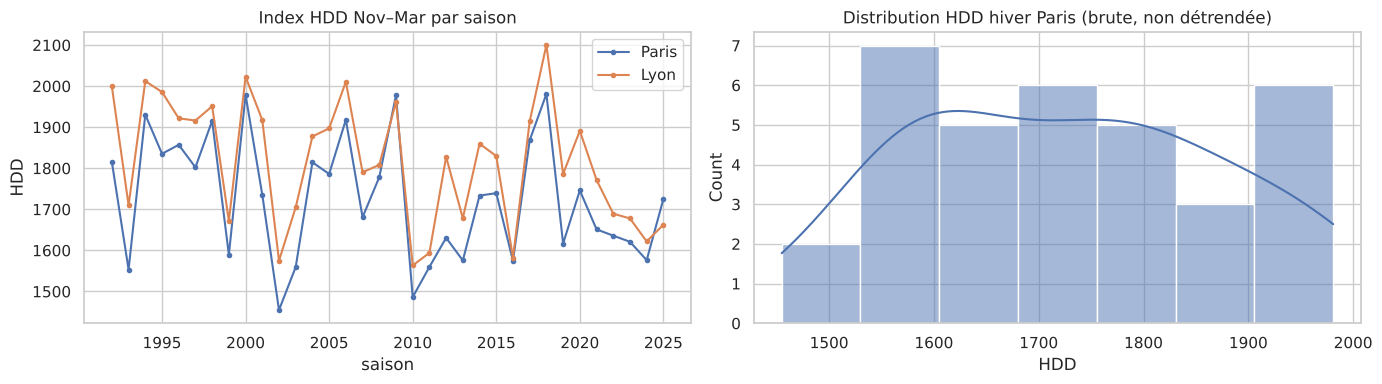

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for city in CITIES:
    hdd_winter[city].plot(ax=axes[0], marker="o", ms=3, label=city)
axes[0].set(title="Index HDD Nov–Mar par saison", ylabel="HDD"); axes[0].legend()
sns.histplot(hdd_winter["Paris"], kde=True, ax=axes[1])
axes[1].set_title("Distribution HDD hiver Paris (brute, non détrendée)")
plt.tight_layout(); plt.show()

In [13]:
# Détrendage d'un index annuel : on ramène chaque année historique au niveau de l'année cible
def detrend_index(idx: pd.Series, target_year: int, method: Literal["linear", "none"] = "linear") -> pd.Series:
    if method == "none":
        return idx.copy()
    years = idx.index.to_numpy(dtype=float)
    slope, intercept = np.polyfit(years, idx.to_numpy(), 1)
    return idx + slope * (target_year - years)


h = hdd_winter["Paris"]
h_adj = detrend_index(h, target_year=2027)
pd.DataFrame({"brut": h.describe(), "détrendé vers 2027": h_adj.describe()}).T

,count,mean,std,min,25%,50%,75%,max
brut,34.00,"1,726.59",149.32,"1,454.75","1,596.24","1,734.35","1,830.24","1,981.00"
détrendé vers 2027,34.00,"1,653.12",143.99,"1,355.47","1,565.99","1,679.04","1,721.94","1,945.26"


## 4. Modèle de température

Modèle standard (Alaton–Djehiche–Stillberger, Benth & Šaltytė-Benth) :

$$T_t = \underbrace{a + b\,t + \sum_{k=1}^{K}\big(c_k \cos(k\omega t) + s_k \sin(k\omega t)\big)}_{\mu_t \text{ (déterministe)}} + \varepsilon_t,\qquad \omega = \tfrac{2\pi}{365.25}$$

$$\varepsilon_t = \sum_{i=1}^{p} \phi_i\,\varepsilon_{t-i} + \sigma_t\, z_t,\qquad z_t \sim \mathcal N(0,1)$$

- Avec $p=1$, c'est la **discrétisation d'un Ornstein-Uhlenbeck** : $d\varepsilon = -\kappa\,\varepsilon\,dt + \sigma dW$ avec $\phi = e^{-\kappa}$, donc $\kappa = -\ln\phi$ et **demi-vie** $= \ln 2 / \kappa$ jours.
- $\sigma_t$ saisonnière : régression de $\eta_t^2$ (résidus AR) sur des harmoniques.
- Diagnostics : ACF/PACF des résidus (choix de $p$), Ljung-Box sur les innovations (plus d'autocorrélation ?), normalité (QQ-plot, Jarque-Bera), skew (l'hiver est souvent asymétrique à gauche : vagues de froid).

C'est exactement le « temperature autocorrelation model » mentionné dans l'annonce.

In [14]:
class TemperatureModel:
    # Tendance + saisonnalité (OLS) + AR(p) sur les résidus + volatilité saisonnière.

    def __init__(self, n_harmonics: int = 2, ar_order: int = 1, vol_harmonics: int = 2):
        self.n_harmonics = n_harmonics
        self.ar_order = ar_order
        self.vol_harmonics = vol_harmonics
        self.is_fitted = False

    # ---------- design matrices ----------
    def _t(self, dates: pd.DatetimeIndex) -> np.ndarray:
        return (dates - self.origin_).days.to_numpy() / 365.25            # en années

    def _harmonics(self, dates: pd.DatetimeIndex, k_max: int) -> np.ndarray:
        w = 2 * np.pi / 365.25
        d = (dates - self.origin_).days.to_numpy()
        cols = []
        for k in range(1, k_max + 1):
            cols += [np.cos(k * w * d), np.sin(k * w * d)]
        return np.column_stack(cols)

    def _X_mean(self, dates):
        return np.column_stack([np.ones(len(dates)), self._t(dates), self._harmonics(dates, self.n_harmonics)])

    def _X_vol(self, dates):
        return np.column_stack([np.ones(len(dates)), self._harmonics(dates, self.vol_harmonics)])

    # ---------- fit ----------
    def fit(self, temp: pd.Series) -> "TemperatureModel":
        temp = temp.dropna().asfreq("D").interpolate(limit=5).dropna()
        self.origin_ = temp.index[0]
        self.temp_ = temp
        X = self._X_mean(temp.index)
        self.ols_ = sm.OLS(temp.to_numpy(), X).fit()
        resid = temp.to_numpy() - self.ols_.predict(X)
        self.resid_ = pd.Series(resid, index=temp.index)

        self.ar_ = AutoReg(resid, lags=self.ar_order, trend="n").fit()
        self.phi_ = np.asarray(self.ar_.params)                          # phi_1..phi_p
        innov = pd.Series(self.ar_.resid, index=temp.index[self.ar_order:])

        Xv = self._X_vol(innov.index)
        self.vol_ols_ = sm.OLS(innov.to_numpy() ** 2, Xv).fit()
        self.innov_ = innov
        self.std_innov_ = innov / self.sigma(innov.index)
        self.is_fitted = True
        return self

    # ---------- composants ----------
    def mean(self, dates: pd.DatetimeIndex) -> np.ndarray:
        return self.ols_.predict(self._X_mean(dates))

    def sigma(self, dates: pd.DatetimeIndex) -> np.ndarray:
        return np.sqrt(np.clip(self.vol_ols_.predict(self._X_vol(dates)), 0.05, None))

    @property
    def kappa(self) -> float:          # vitesse de retour à la moyenne (AR1 ≈ OU)
        return -np.log(self.phi_[0])

    @property
    def half_life_days(self) -> float:
        return np.log(2) / self.kappa

    def summary(self) -> pd.Series:
        p = self.ols_.params
        amp = np.hypot(p[2], p[3])
        return pd.Series({
            "niveau a (°C)": p[0], "tendance b (°C/an)": p[1],
            "amplitude 1re harmonique": amp,
            **{f"phi_{i+1}": v for i, v in enumerate(self.phi_)},
            "kappa (1/jour)": self.kappa, "demi-vie (jours)": self.half_life_days,
            "R² partie déterministe": self.ols_.rsquared,
            "sigma moyen": self.sigma(self.temp_.index).mean(),
        })

    # ---------- simulation ----------
    def simulate_path(self, last_resids: np.ndarray, dates: pd.DatetimeIndex, n_sims: int,
                      rng: np.random.Generator, z: Optional[np.ndarray] = None) -> np.ndarray:
        # Renvoie un array (n_jours, n_sims). Boucle sur les jours, vectorisé sur les scénarios.
        p, n = self.ar_order, len(dates)
        mu, sig = self.mean(dates), self.sigma(dates)
        if z is None:
            z = rng.standard_normal((n, n_sims))
        e = np.empty((n + p, n_sims))
        e[:p] = np.asarray(last_resids[-p:])[:, None]
        for i in range(n):
            ar = sum(self.phi_[k] * e[p + i - 1 - k] for k in range(p))
            e[p + i] = ar + sig[i] * z[i]
        return mu[:, None] + e[p:]

    def simulate(self, start, end, n_sims: int = 10_000, rng: Optional[np.random.Generator] = None,
                 history: Optional[pd.Series] = None, z: Optional[np.ndarray] = None) -> pd.DataFrame:
        # Simule de la dernière obs. de `history` jusqu'à `end`, renvoie la fenêtre [start, end].
        # Passer un `history` qui s'arrête en cours de saison = simulation CONDITIONNELLE.
        rng = rng if rng is not None else np.random.default_rng()
        history = self.temp_ if history is None else history
        last = history.index[-1]
        dates = pd.date_range(last + pd.Timedelta(days=1), pd.Timestamp(end), freq="D")
        last_res = history.to_numpy()[-self.ar_order:] - self.mean(history.index[-self.ar_order:])
        paths = self.simulate_path(last_res, dates, n_sims, rng, z)
        return pd.DataFrame(paths, index=dates).loc[pd.Timestamp(start):]

    def sim_dates(self, end, history: Optional[pd.Series] = None) -> pd.DatetimeIndex:
        history = self.temp_ if history is None else history
        return pd.date_range(history.index[-1] + pd.Timedelta(days=1), pd.Timestamp(end), freq="D")


models = {city: TemperatureModel(n_harmonics=2, ar_order=1).fit(t) for city, t in T.items()}
pd.DataFrame({c: m.summary() for c, m in models.items()})

,Paris,Lyon
niveau a (°C),11.62,12.02
tendance b (°C/an),0.04,0.04
amplitude 1re harmonique,7.74,9.29
phi_1,0.75,0.73
kappa (1/jour),0.28,0.32
demi-vie (jours),2.45,2.17
R² partie déterministe,0.67,0.74
sigma moyen,2.49,2.66


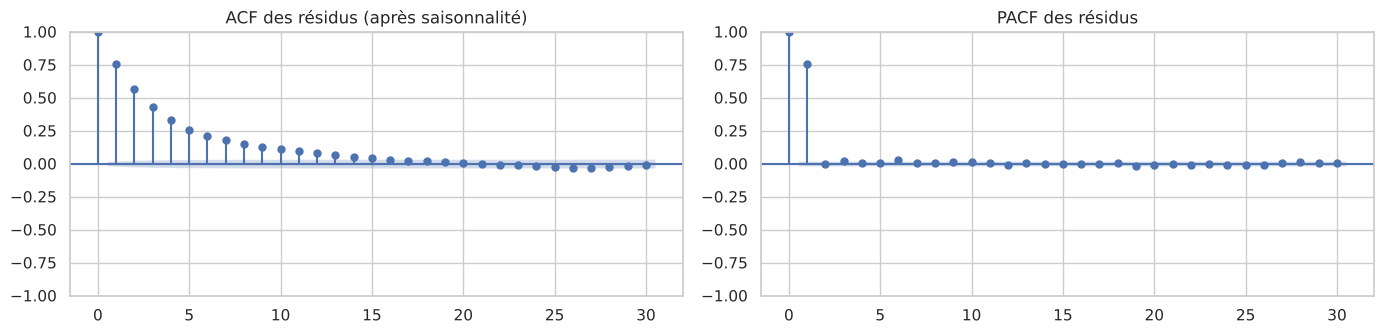

Ordre AR retenu par BIC : [1]


In [15]:
# Choix de l'ordre AR : PACF + critère d'information
m = models["Paris"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(m.resid_, lags=30, ax=axes[0], title="ACF des résidus (après saisonnalité)")
plot_pacf(m.resid_, lags=30, ax=axes[1], title="PACF des résidus", method="ywm")
plt.tight_layout(); plt.show()

sel = ar_select_order(m.resid_.to_numpy(), maxlag=10, ic="bic", trend="n")
print("Ordre AR retenu par BIC :", sel.ar_lags)

In [16]:
# Ordre AR(3) pour comparaison : souvent retenu dans la littérature (Benth)
m3 = TemperatureModel(n_harmonics=2, ar_order=3).fit(T["Paris"])
print("AR(1) AIC :", round(m.ar_.aic, 1), "| AR(3) AIC :", round(m3.ar_.aic, 1))
print("phi AR(3) :", np.round(m3.phi_, 3))

AR(1) AIC : 59859.1 | AR(3) AIC : 59850.9
phi AR(3) : [ 0.759 -0.019  0.016]


Ljung-Box (H0 : pas d'autocorrélation) :
     lb_stat  lb_pvalue
5      3.58       0.61
10    12.87       0.23
20    21.09       0.39

Jarque-Bera p-value = 7.55e-01 | skew = -0.011 | kurtosis excès = 0.023


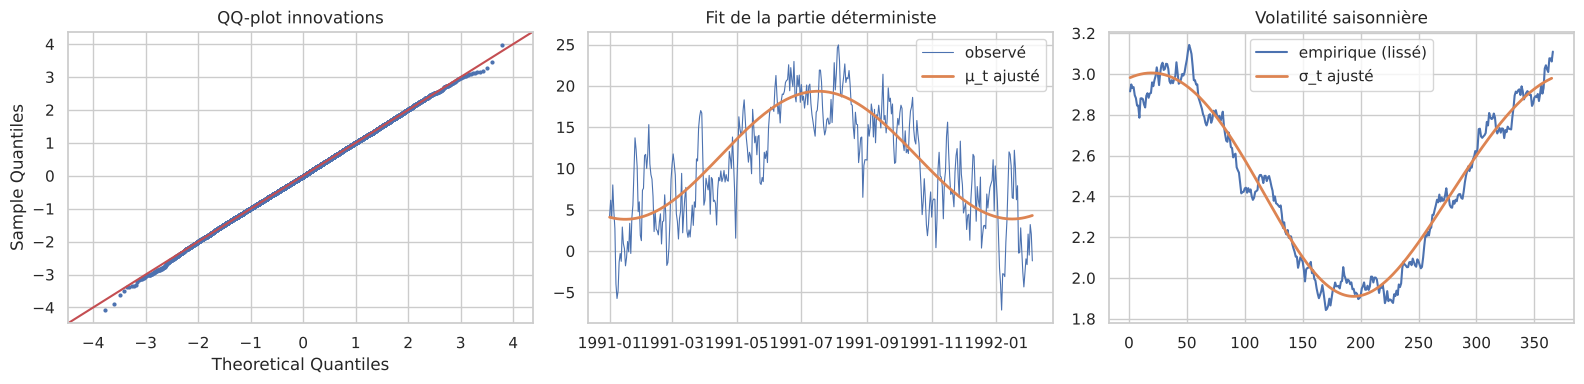

In [17]:
# Diagnostics des innovations standardisées
z_std = m.std_innov_
lb = acorr_ljungbox(z_std, lags=[5, 10, 20], return_df=True)
jb = stats.jarque_bera(z_std)
print("Ljung-Box (H0 : pas d'autocorrélation) :\n", lb.round(3))
print(f"\nJarque-Bera p-value = {jb.pvalue:.2e} | skew = {stats.skew(z_std):.3f} | kurtosis excès = {stats.kurtosis(z_std):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sm.qqplot(z_std, line="45", ax=axes[0], markersize=2); axes[0].set_title("QQ-plot innovations")
doy_idx = m.temp_.index[:400]
axes[1].plot(m.temp_.loc[doy_idx], lw=0.8, label="observé")
axes[1].plot(doy_idx, m.mean(doy_idx), lw=2, label="μ_t ajusté"); axes[1].legend()
axes[1].set_title("Fit de la partie déterministe")
emp_vol = m.innov_.groupby(m.innov_.index.dayofyear).std().rolling(15, center=True, min_periods=1).mean()
year_dates = pd.date_range("2025-01-01", "2025-12-31")
axes[2].plot(emp_vol.index, emp_vol.values, label="empirique (lissé)")
axes[2].plot(year_dates.dayofyear, m.sigma(year_dates), lw=2, label="σ_t ajusté")
axes[2].set_title("Volatilité saisonnière"); axes[2].legend()
plt.tight_layout(); plt.show()

## 5. Simulation Monte Carlo

On simule depuis la dernière observation jusqu'à la fin de la période de risque (la mémoire AR s'éteint naturellement avant le début de la saison).
**Vectorisation :** boucle Python sur les ~500 jours uniquement, toutes les simulations sont traitées en même temps par NumPy.

**Validation :** la distribution simulée de l'index doit ressembler à la distribution historique **détrendée**. Si l'écart-type simulé est trop faible, c'est souvent que l'autocorrélation est sous-estimée (AR(1) vs AR(3)) — c'est un point d'amélioration typique du modèle.

(151, 20000) (jours x scénarios)


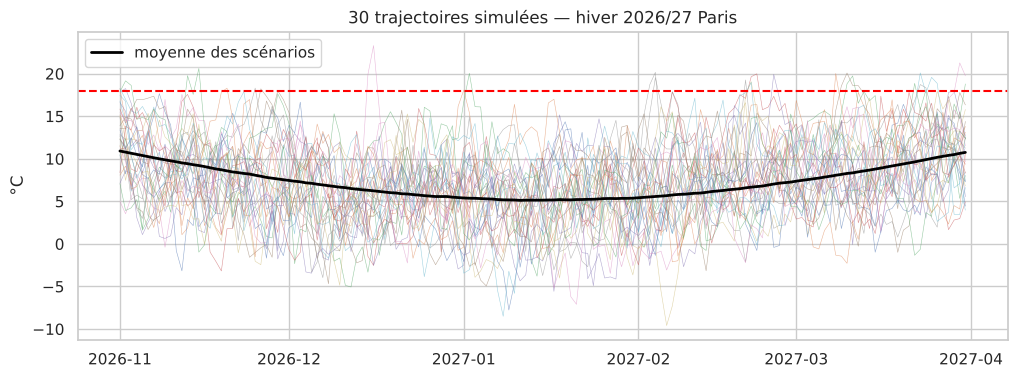

In [18]:
N_SIMS = 20_000
sim_winter = models["Paris"].simulate(*WINTER, n_sims=N_SIMS, rng=np.random.default_rng(1))
print(sim_winter.shape, "(jours x scénarios)")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sim_winter.iloc[:, :30], lw=0.4, alpha=0.6)
ax.plot(sim_winter.mean(axis=1), color="black", lw=2, label="moyenne des scénarios")
ax.axhline(BASE_TEMP, ls="--", color="red")
ax.set(title="30 trajectoires simulées — hiver 2026/27 Paris", ylabel="°C"); ax.legend(); plt.show()

,mean,std,min,50%,max
historique détrendé,"1,653.12",143.99,"1,355.47","1,679.04","1,945.26"
Monte Carlo AR(1),"1,634.55",141.02,"1,027.48","1,635.24","2,168.06"


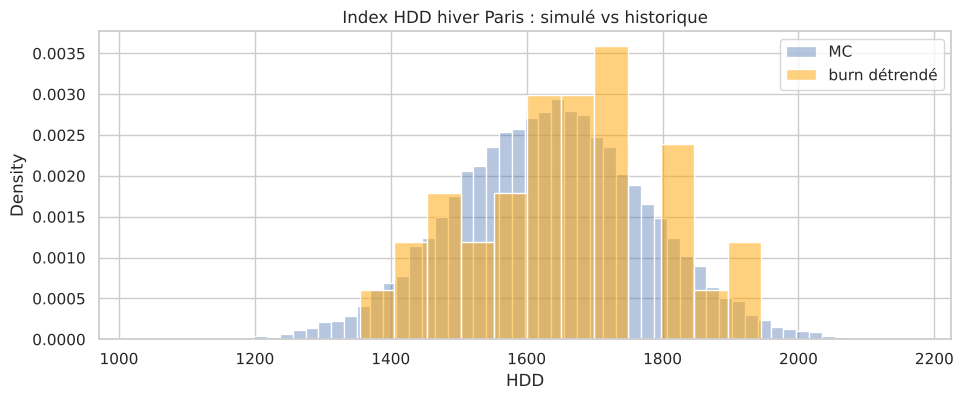

In [19]:
def index_from_paths(paths: pd.DataFrame | np.ndarray, kind: str = "HDD", base: float = BASE_TEMP) -> np.ndarray:
    x = np.asarray(paths)
    if kind == "HDD":
        return np.maximum(base - x, 0).sum(axis=0)
    if kind == "CDD":
        return np.maximum(x - base, 0).sum(axis=0)
    if kind == "CAT":
        return x.sum(axis=0)
    raise ValueError(kind)


hdd_sim = index_from_paths(sim_winter, "HDD")
hist_adj = detrend_index(hdd_winter["Paris"], 2027)

comp = pd.DataFrame({"historique détrendé": hist_adj.describe(),
                     "Monte Carlo AR(1)": pd.Series(hdd_sim).describe()}).T
display(comp[["mean", "std", "min", "50%", "max"]])

fig, ax = plt.subplots()
sns.histplot(hdd_sim, stat="density", bins=60, alpha=0.4, label="MC", ax=ax)
sns.histplot(hist_adj, stat="density", bins=12, color="orange", alpha=0.5, label="burn détrendé", ax=ax)
ax.set(title="Index HDD hiver Paris : simulé vs historique", xlabel="HDD"); ax.legend(); plt.show()

In [20]:
# Effet de l'ordre AR sur la variance de l'index (point de discussion en entretien)
hdd_sim3 = index_from_paths(m3.simulate(*WINTER, n_sims=N_SIMS, rng=np.random.default_rng(1)), "HDD")
print(f"Std index : histo détrendé {hist_adj.std():.1f} | AR(1) {hdd_sim.std():.1f} | AR(3) {hdd_sim3.std():.1f}")

Std index : histo détrendé 144.0 | AR(1) 141.0 | AR(3) 142.3


## 6. Architecture orientée objet

Ce que les recruteurs regardent : séparation claire **produit** (ce qu'on vend) / **méthode** (comment on price) / **résultat**.

- `WeatherContract` : `@dataclass(frozen=True)`, validation dans `__post_init__`, méthode `payoff()` vectorisée.
- `Pricer` (classe abstraite, `ABC`) : implémente le *template method* `price()` ; les sous-classes ne fournissent que `index_distribution()`.
- `BurnPricer`, `IndexDistributionPricer` (loi normale, formule fermée), `MonteCarloPricer`.
- `PricingResult` : dataclass de sortie, facile à empiler dans un `DataFrame`.

**Payoffs** (tick $\tau$ en €/DD, strike $K$, cap $C$, index $I$) :
- Call : $\min(\tau\,(I-K)^+,\ C)$ — protège contre un index élevé (hiver froid pour un HDD, été chaud pour un CDD)
- Put : $\min(\tau\,(K-I)^+,\ C)$ — protège contre un index faible (hiver doux → baisse des ventes de gaz)
- Swap : $\mathrm{clip}(\tau\,(I-K),\ -C,\ C)$ — symétrique, pas de prime

**Prix :** pas de réplication possible (la température ne se trade pas) → pricing **actuariel** :
$\text{Prix} = DF \times \big(E[X] + \lambda \cdot \text{risque}\big)$, avec risque = écart-type, ou CVaR, ou coût du capital.

In [21]:
IndexType = Literal["HDD", "CDD", "CAT"]
OptionType = Literal["call", "put", "swap"]


@dataclass(frozen=True)
class WeatherContract:
    name: str
    city: str
    index_type: IndexType
    option_type: OptionType
    strike: float
    tick: float                      # €/degree-day
    start: pd.Timestamp
    end: pd.Timestamp
    cap: float = np.inf              # paiement max (€)
    position: int = 1                # +1 acheteur, -1 vendeur
    base: float = BASE_TEMP
    payment_lag_days: int = 30

    def __post_init__(self):
        object.__setattr__(self, "start", pd.Timestamp(self.start))
        object.__setattr__(self, "end", pd.Timestamp(self.end))
        if self.end <= self.start:
            raise ValueError("end doit être après start")
        if self.tick <= 0 or self.cap <= 0:
            raise ValueError("tick et cap doivent être > 0")
        if self.position not in (1, -1):
            raise ValueError("position = +1 ou -1")
        if self.option_type not in ("call", "put", "swap"):
            raise ValueError(f"option_type inconnu : {self.option_type}")

    @property
    def n_days(self) -> int:
        return (self.end - self.start).days + 1

    @property
    def window_md(self) -> tuple[tuple[int, int], tuple[int, int]]:
        return (self.start.month, self.start.day), (self.end.month, self.end.day)

    def index_from_temps(self, temps) -> np.ndarray:
        return index_from_paths(temps, self.index_type, self.base)

    def payoff(self, index_values) -> np.ndarray:
        I = np.asarray(index_values, dtype=float)
        K, tau, C = self.strike, self.tick, self.cap
        if self.option_type == "call":
            raw = np.minimum(tau * np.maximum(I - K, 0.0), C)
        elif self.option_type == "put":
            raw = np.minimum(tau * np.maximum(K - I, 0.0), C)
        else:
            raw = np.clip(tau * (I - K), -C, C)
        return self.position * raw

    def with_(self, **changes) -> "WeatherContract":   # copie modifiée (frozen)
        d = asdict(self); d.update(changes)
        return WeatherContract(**d)

    def describe(self) -> str:
        sens = "Long" if self.position == 1 else "Short"
        cap = "sans cap" if np.isinf(self.cap) else f"cap {self.cap:,.0f} €"
        return (f"{sens} {self.option_type} {self.index_type} {self.city} "
                f"{self.start:%d/%m/%Y}–{self.end:%d/%m/%Y}, K={self.strike:,.0f}, "
                f"tick={self.tick:,.0f} €/DD, {cap}")


@dataclass
class PricingResult:
    contract: str
    method: str
    index_mean: float
    index_std: float
    expected_payoff: float
    payoff_std: float
    prob_payout: float
    var_95: float          # perte au 5e percentile du P&L du DÉTENTEUR (valeur négative = perte)
    cvar_95: float
    discount_factor: float
    fair_value: float      # DF * E[payoff]
    ask: float             # prix proposé par le desk vendeur : DF*(E + lambda*std)
    bid: float

    def to_series(self) -> pd.Series:
        return pd.Series(asdict(self))

In [22]:
class Pricer(ABC):
    method_name = "abstract"

    def __init__(self, rate: float = RATE, loading: float = 0.20,
                 valuation_date: pd.Timestamp = VALUATION_DATE):
        self.rate = rate
        self.loading = loading           # lambda : chargement en multiple d'écart-type
        self.valuation_date = pd.Timestamp(valuation_date)

    def discount_factor(self, c: WeatherContract) -> float:
        pay_date = c.end + pd.Timedelta(days=c.payment_lag_days)
        tau = max((pay_date - self.valuation_date).days, 0) / 365.25
        return float(np.exp(-self.rate * tau))

    @abstractmethod
    def index_distribution(self, c: WeatherContract) -> np.ndarray:
        # Échantillon (ou historique) de valeurs possibles de l'index.
        ...

    def price(self, c: WeatherContract) -> PricingResult:
        idx = self.index_distribution(c)
        pay = c.payoff(idx)
        df = self.discount_factor(c)
        q05 = np.quantile(pay, 0.05)
        tail = pay[pay <= q05]
        e, sd = pay.mean(), pay.std(ddof=1)
        return PricingResult(
            contract=c.name, method=self.method_name,
            index_mean=idx.mean(), index_std=idx.std(ddof=1),
            expected_payoff=e, payoff_std=sd,
            prob_payout=float((np.abs(pay) > 1e-9).mean()),
            var_95=q05, cvar_95=tail.mean() if len(tail) else q05,
            discount_factor=df, fair_value=df * e,
            ask=df * (e + self.loading * sd), bid=df * (e - self.loading * sd),
        )

    def price_many(self, contracts: list[WeatherContract]) -> pd.DataFrame:
        return pd.DataFrame([self.price(c).to_series() for c in contracts]).set_index(["contract", "method"])


class BurnPricer(Pricer):
    # Burn analysis : on applique le payoff aux N dernières saisons historiques (détrendées).
    method_name = "burn"

    def __init__(self, temps: dict[str, pd.Series], n_years: int = 30,
                 detrend: Literal["linear", "none"] = "linear", **kw):
        super().__init__(**kw)
        self.temps, self.n_years, self.detrend = temps, n_years, detrend

    def historical_index(self, c: WeatherContract) -> pd.Series:
        daily = degree_days(self.temps[c.city], c.base)[c.index_type]
        start_md, end_md = c.window_md
        idx = seasonal_index(daily, start_md, end_md).tail(self.n_years)
        return detrend_index(idx, c.end.year, self.detrend)

    def index_distribution(self, c):
        return self.historical_index(c).to_numpy()


class IndexDistributionPricer(BurnPricer):
    # Ajuste une loi normale sur l'index détrendé. Formule fermée si pas de cap.
    method_name = "index normal"

    def __init__(self, *a, n_draws: int = 200_000, seed: int = 0, **kw):
        super().__init__(*a, **kw)
        self.n_draws, self.seed = n_draws, seed

    def fit(self, c):
        h = self.historical_index(c)
        return h.mean(), h.std(ddof=1)

    def index_distribution(self, c):
        mu, sd = self.fit(c)
        return np.random.default_rng(self.seed).normal(mu, sd, self.n_draws)

    def closed_form(self, c: WeatherContract) -> float:
        # E[tau (I-K)+] = tau [ (mu-K) Phi(d) + sd phi(d) ],  d = (mu-K)/sd  (Bachelier)
        mu, sd = self.fit(c)
        if c.option_type == "swap":
            return c.position * self.discount_factor(c) * c.tick * (mu - c.strike)
        d = (mu - c.strike) / sd if c.option_type == "call" else (c.strike - mu) / sd
        intrinsic = (mu - c.strike) if c.option_type == "call" else (c.strike - mu)
        ev = c.tick * (intrinsic * stats.norm.cdf(d) + sd * stats.norm.pdf(d))
        return c.position * self.discount_factor(c) * ev


class MonteCarloPricer(Pricer):
    method_name = "monte carlo"

    def __init__(self, models: dict[str, TemperatureModel], n_sims: int = 20_000,
                 seed: int = 123, history: Optional[dict[str, pd.Series]] = None, **kw):
        super().__init__(**kw)
        self.models, self.n_sims, self.seed = models, n_sims, seed
        self.history = history or {}
        self._cache: dict = {}

    def simulate(self, c: WeatherContract) -> pd.DataFrame:
        hist = self.history.get(c.city)
        key = (c.city, c.start, c.end, None if hist is None else hist.index[-1])
        if key not in self._cache:
            rng = np.random.default_rng(self.seed)
            self._cache[key] = self.models[c.city].simulate(c.start, c.end, self.n_sims, rng, history=hist)
        return self._cache[key]

    def index_distribution(self, c):
        return c.index_from_temps(self.simulate(c))

## 7. Pricing

On définit quelques contrats typiques et on compare les trois méthodes.
Strike « at-the-money » = index attendu. Tick et cap réalistes pour un client B2B.

In [23]:
burn = BurnPricer(T, n_years=30)
normal = IndexDistributionPricer(T, n_years=30)
mc = MonteCarloPricer(models, n_sims=N_SIMS)

base_put = WeatherContract("Put HDD Paris ATM", "Paris", "HDD", "put", strike=0, tick=5_000,
                           start=WINTER[0], end=WINTER[1], cap=1_500_000)
K_atm = round(burn.historical_index(base_put).mean(), -1)
put_atm = base_put.with_(strike=K_atm)

contracts = [
    put_atm,
    put_atm.with_(name="Put HDD Paris OTM (-150)", strike=K_atm - 150),
    put_atm.with_(name="Call HDD Paris ATM", option_type="call"),
    put_atm.with_(name="Swap HDD Paris", option_type="swap"),
    WeatherContract("Call CDD Paris été", "Paris", "CDD", "call", strike=0, tick=8_000,
                    start=SUMMER[0], end=SUMMER[1], cap=1_000_000),
]
cdd_atm = round(burn.historical_index(contracts[-1]).mean(), -1)
contracts[-1] = contracts[-1].with_(strike=cdd_atm)

for c in contracts:
    print("•", c.describe())

• Long put HDD Paris 01/11/2026–31/03/2027, K=1,650, tick=5,000 €/DD, cap 1,500,000 €
• Long put HDD Paris 01/11/2026–31/03/2027, K=1,500, tick=5,000 €/DD, cap 1,500,000 €
• Long call HDD Paris 01/11/2026–31/03/2027, K=1,650, tick=5,000 €/DD, cap 1,500,000 €
• Long swap HDD Paris 01/11/2026–31/03/2027, K=1,650, tick=5,000 €/DD, cap 1,500,000 €
• Long call CDD Paris 01/05/2027–30/09/2027, K=260, tick=8,000 €/DD, cap 1,000,000 €


In [24]:
results = pd.concat([p.price_many(contracts) for p in (burn, normal, mc)]).sort_index()
cols = ["index_mean", "index_std", "fair_value", "ask", "bid", "prob_payout", "var_95"]
results[cols]

index_mean  index_std  fair_value        ask         bid  prob_payout        var_95
contract                 method                                                                                           
Call CDD Paris été       burn              256.86      50.28  143,900.20 190,178.39   97,622.01         0.50          0.00
                         index normal      256.87      50.34  143,201.75 186,482.67   99,920.84         0.48          0.00
                         monte carlo       273.81      64.08  244,292.35 305,857.39  182,727.32         0.57          0.00
Call HDD Paris ATM       burn            1,650.43     144.32  284,979.49 368,499.02  201,459.96         0.50          0.00
                         index normal    1,650.45     144.49  279,760.07 359,353.17  200,166.97         0.50          0.00
                         monte carlo     1,635.48     140.66  238,692.83 312,302.62  165,083.03         0.46          0.00
Put HDD Paris ATM        burn            1,650.43     144.32  282,846.22 363,560.15  202,132.30         0.50          0.00
                         index normal    1,650.45     144.49  277,501.04 356,882.06  198,120.02         0.50          0.00
                         monte carlo     1,635.48     140.66  307,798.46 389,698.55  225,898.37         0.54          0.00
Put HDD Paris OTM (-150) burn            1,650.43     144.32   50,400.15  81,292.23   19,508.07         0.17          0.00
                         index normal    1,650.45     144.49   54,561.96  89,955.36   19,168.55         0.15          0.00
                         monte carlo     1,635.48     140.66   61,281.38  98,422.09   24,140.68         0.17          0.00
Swap HDD Paris           burn            1,650.43     144.32    2,133.27 144,122.84 -139,856.31         1.00 -1,072,403.71
                         index normal    1,650.45     144.49    2,259.02 139,543.89 -135,025.85         1.00 -1,184,193.00
                         monte carlo     1,635.48     140.66  -69,105.63  65,072.84 -203,284.11         1.00 -1,229,754.53

In [25]:
# Vérif formule fermée (sans cap) vs simulation
c_nocap = put_atm.with_(cap=np.inf)
print(f"Formule fermée Bachelier : {normal.closed_form(c_nocap):,.0f} €")
print(f"Tirages loi normale     : {normal.price(c_nocap).fair_value:,.0f} €")

Formule fermée Bachelier : 282,163 €
Tirages loi normale     : 282,484 €


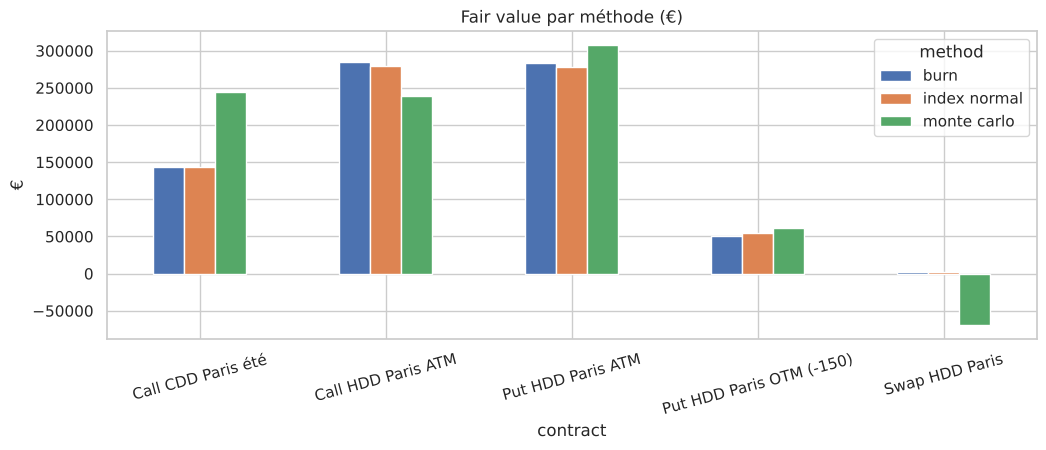

In [26]:
# Graphique comparatif
fv = results["fair_value"].unstack("method")
fv.plot.bar(figsize=(12, 4), rot=15, title="Fair value par méthode (€)"); plt.ylabel("€"); plt.show()

**Lecture :**
- Le burn analysis dépend fortement du détrendage et du nombre d'années (petit échantillon : 30 points).
- La loi normale lisse les queues mais peut sous-estimer l'asymétrie.
- Le Monte Carlo exploite toute l'information journalière, mais il dépend du modèle (ordre AR, vol saisonnière). Un trader regarde les trois et explique les écarts.

In [27]:
# Sensibilité au nombre d'années et au détrendage (burn)
rows = []
for n in (10, 15, 20, 25, 30):
    for d in ("none", "linear"):
        r = BurnPricer(T, n_years=n, detrend=d).price(put_atm)
        rows.append({"années": n, "détrendage": d, "fair_value": r.fair_value, "index_mean": r.index_mean})
sens_burn = pd.DataFrame(rows).pivot(index="années", columns="détrendage", values="fair_value")
sens_burn

détrendage,linear,none
années,,
10,"394,803.55","110,931.20"
15,"92,668.69","134,347.27"
20,"278,184.28","141,037.58"
25,"194,422.32","169,048.32"
30,"282,846.22","150,810.67"


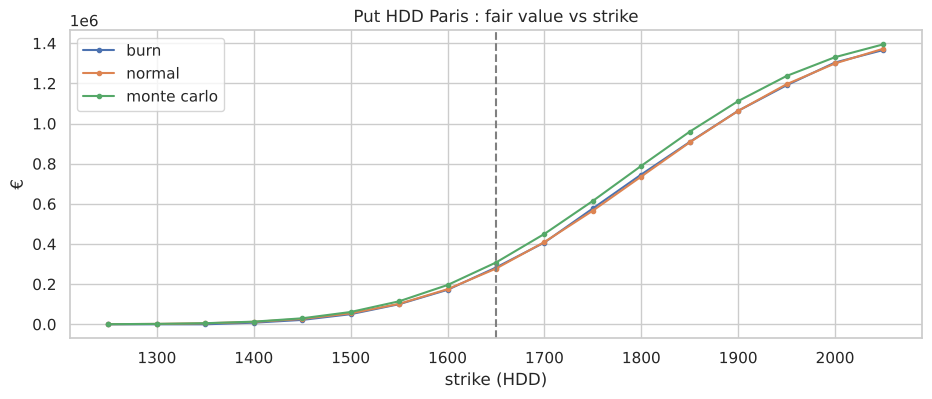

In [28]:
# Profil du prix en fonction du strike
strikes = np.linspace(K_atm - 400, K_atm + 400, 17)
profile = pd.DataFrame({
    name: [p.price(put_atm.with_(strike=k)).fair_value for k in strikes]
    for name, p in [("burn", burn), ("normal", normal), ("monte carlo", mc)]
}, index=strikes)
ax = profile.plot(marker="o", ms=3, title="Put HDD Paris : fair value vs strike")
ax.axvline(K_atm, ls="--", color="grey"); ax.set(xlabel="strike (HDD)", ylabel="€"); plt.show()

,moyenne,écart-type entre seeds
n_sims,,
500,"310,790.78","8,188.67"
1000,"306,777.77","21,560.20"
2000,"311,603.39","4,091.90"
5000,"307,815.72","10,233.42"
10000,"311,539.99","2,809.35"
20000,"306,962.31","2,639.57"


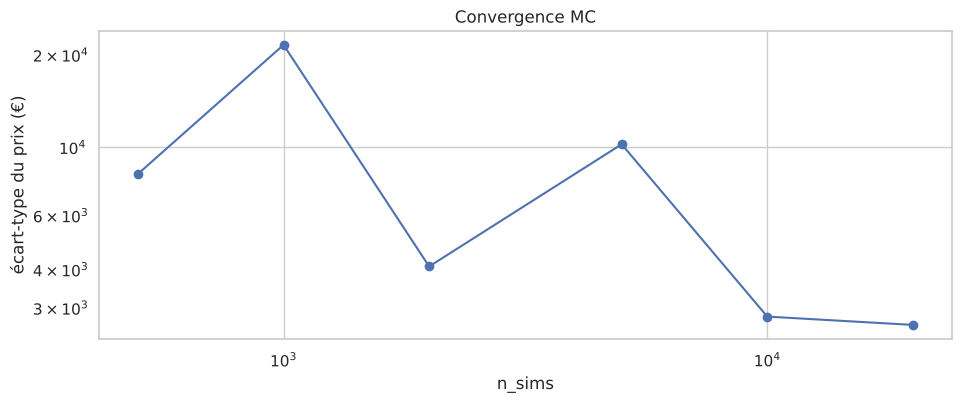

In [29]:
# Convergence Monte Carlo : erreur standard ~ 1/sqrt(N)
rows = []
for n in (500, 1_000, 2_000, 5_000, 10_000, 20_000):
    vals = [MonteCarloPricer(models, n_sims=n, seed=s).price(put_atm).fair_value for s in range(5)]
    rows.append({"n_sims": n, "moyenne": np.mean(vals), "écart-type entre seeds": np.std(vals)})
conv = pd.DataFrame(rows).set_index("n_sims")
display(conv)
ax = conv["écart-type entre seeds"].plot(logx=True, logy=True, marker="o", title="Convergence MC")
ax.set_ylabel("écart-type du prix (€)"); plt.show()

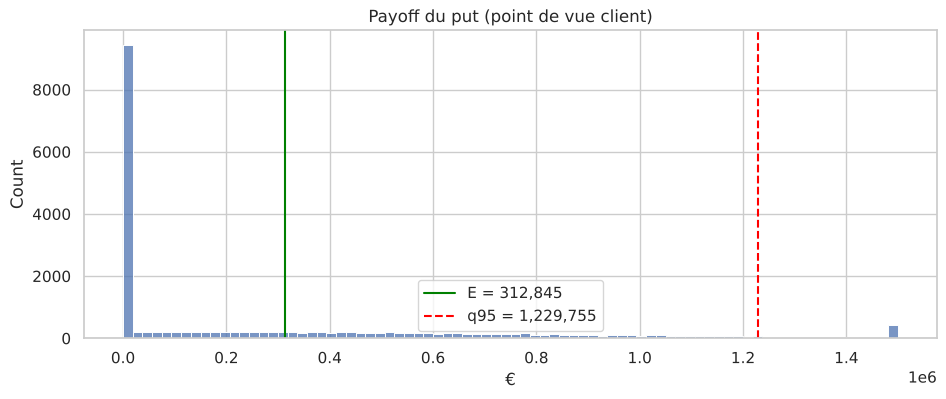

P&L desk : moyenne 83,243 €, VaR95 -833,667 €, CVaR95 -1,010,696 €, P(perte) 32.4%


In [30]:
# Distribution du payoff + mesures de risque pour le desk vendeur du put
pay = put_atm.payoff(mc.index_distribution(put_atm))
r = mc.price(put_atm)
fig, ax = plt.subplots()
sns.histplot(pay, bins=80, ax=ax)
ax.axvline(r.expected_payoff, color="green", label=f"E = {r.expected_payoff:,.0f}")
ax.axvline(np.quantile(pay, 0.95), color="red", ls="--", label=f"q95 = {np.quantile(pay, .95):,.0f}")
ax.set(title="Payoff du put (point de vue client)", xlabel="€"); ax.legend(); plt.show()

desk_pnl = r.ask / r.discount_factor - pay          # desk : encaisse la prime, paie le payoff
print(f"P&L desk : moyenne {desk_pnl.mean():,.0f} €, VaR95 {np.quantile(desk_pnl, .05):,.0f} €, "
      f"CVaR95 {desk_pnl[desk_pnl <= np.quantile(desk_pnl, .05)].mean():,.0f} €, P(perte) {(desk_pnl < 0).mean():.1%}")

In [31]:
# Prime de risque basée sur la CVaR (alternative au lambda * sigma) : coût du capital
def price_cost_of_capital(pay: np.ndarray, df: float, coc: float = 0.10) -> float:
    # Point de vue vendeur : capital = perte extrême (moyenne du pire 1 %) moins la perte attendue
    e = pay.mean()
    capital = np.mean(pay[pay >= np.quantile(pay, 0.99)]) - e
    return df * (e + coc * capital)

print(f"Prix coût du capital (10% x CVaR99) : {price_cost_of_capital(pay, r.discount_factor):,.0f} € "
      f"vs ask lambda*sigma : {r.ask:,.0f} €")

Prix coût du capital (10% x CVaR99) : 424,599 € vs ask lambda*sigma : 389,699 €


## 8. Cas client : couvrir un fournisseur de gaz contre un hiver doux

Démarche front office classique :
1. **Quantifier l'exposition** : régression volume ↔ HDD sur l'historique client → sensibilité $\beta$ (MWh/HDD).
2. **Traduire en €** : marge unitaire $m$ (€/MWh) × $\beta$ = **€ perdus par HDD manquant** → c'est le tick naturel.
3. **Structurer** : put HDD (paye une prime, garde l'upside), swap (gratuit, rend l'upside), collar zero-cost (put acheté + call vendu).
4. **Montrer l'effet** sur la distribution du P&L : écart-type, VaR, probabilité de rater le budget.

Les données de consommation ci-dessous sont **fictives**, générées à partir des températures réelles.

beta = 4008.5 MWh/HDD | R² = 0.989
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.994e+04     51.581    386.581      0.000    1.98e+04       2e+04
HDD         4008.4775      5.634    711.487      0.000    3997.433    4019.522
weekend    -1591.3242     72.071    -22.080      0.000   -1732.610   -1450.038


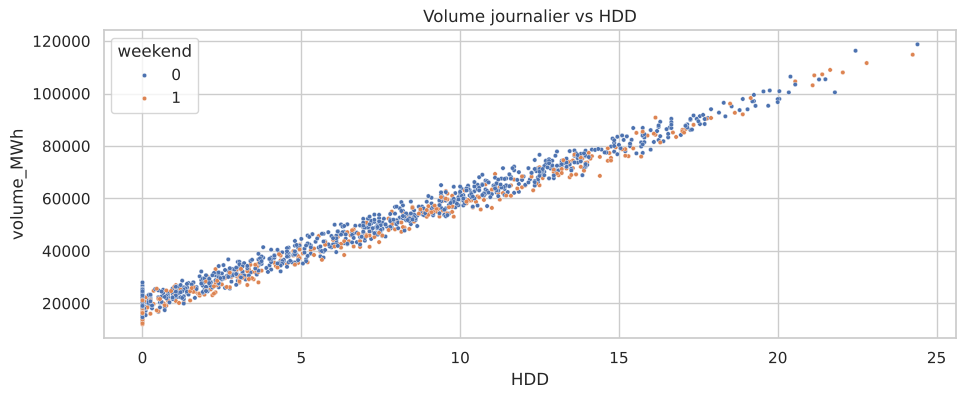

In [32]:
# --- Données client fictives : consommation journalière d'un portefeuille B2C (MWh) ---
rng_c = np.random.default_rng(7)
hist_temp = T["Paris"].loc["2010":"2025"]
hdd_daily = degree_days(hist_temp)["HDD"]
weekday_effect = np.where(hist_temp.index.dayofweek >= 5, -1_500, 0)
volume = 20_000 + 4_000 * hdd_daily + weekday_effect + rng_c.normal(0, 2_500, len(hdd_daily))
client = pd.DataFrame({"volume_MWh": volume.clip(lower=0), "HDD": hdd_daily,
                       "weekend": (hist_temp.index.dayofweek >= 5).astype(int)})

# Régression sklearn (+ statsmodels pour les intervalles de confiance)
Xc = client[["HDD", "weekend"]]
reg = LinearRegression().fit(Xc, client["volume_MWh"])
ols_client = sm.OLS(client["volume_MWh"], sm.add_constant(Xc)).fit()
beta = reg.coef_[0]
print(f"beta = {beta:.1f} MWh/HDD | R² = {r2_score(client['volume_MWh'], reg.predict(Xc)):.3f}")
print(ols_client.summary().tables[1])

sns.scatterplot(data=client.sample(1500, random_state=0), x="HDD", y="volume_MWh", hue="weekend", s=10)
plt.title("Volume journalier vs HDD"); plt.show()

In [33]:
MARGIN = 9.0                                  # €/MWh
exposure_per_hdd = MARGIN * beta              # € perdus par HDD manquant
print(f"Exposition : {exposure_per_hdd:,.0f} € par HDD")

# P&L saisonnier (gross margin vs budget) en fonction de l'index HDD simulé
I_sim = mc.index_distribution(put_atm)
n_days = put_atm.n_days
expected_I = I_sim.mean()


def client_margin(I):
    return MARGIN * (reg.intercept_ * n_days + beta * I)


budget = client_margin(expected_I)
pnl_unhedged = client_margin(I_sim) - budget


def risk_stats(x: np.ndarray, label: str) -> dict:
    q = np.quantile(x, 0.05)
    return {"stratégie": label, "moyenne": x.mean(), "écart-type": x.std(),
            "VaR95": q, "CVaR95": x[x <= q].mean(), "P(< -1M€)": (x < -1e6).mean()}

print(f"Budget de marge : {budget/1e6:,.1f} M€")

Exposition : 36,076 € par HDD


Budget de marge : 86.1 M€


In [34]:
# --- Stratégie 1 : put HDD, tick = exposition, strike ATM ---
hedge_put = WeatherContract("Hedge put", "Paris", "HDD", "put", strike=round(expected_I, -1),
                            tick=round(exposure_per_hdd, -2), start=WINTER[0], end=WINTER[1],
                            cap=12_000_000)
prem_put = mc.price(hedge_put).ask / mc.price(hedge_put).discount_factor   # prime capitalisée à l'échéance
pnl_put = pnl_unhedged + hedge_put.payoff(I_sim) - prem_put

# --- Stratégie 2 : swap HDD (pas de prime) ---
hedge_swap = hedge_put.with_(name="Hedge swap", option_type="swap")
pnl_swap = pnl_unhedged + hedge_swap.payoff(I_sim) * -1        # client VEND le swap : reçoit si I < K

# --- Stratégie 3 : collar zero-cost (achète put K_put, vend call K_call) ---
K_put = round(expected_I - 100, -1)
put_leg = hedge_put.with_(name="put leg", strike=K_put)
call_leg = hedge_put.with_(name="call leg", option_type="call", position=-1)
put_fv = mc.price(put_leg).fair_value


def collar_net(k_call):
    return mc.price(call_leg.with_(strike=k_call)).fair_value + put_fv     # call vendu => valeur négative

K_call = brentq(collar_net, expected_I, expected_I + 1500)
call_leg = call_leg.with_(strike=K_call)
pnl_collar = pnl_unhedged + put_leg.payoff(I_sim) + call_leg.payoff(I_sim)
print(f"Collar zero-cost : put K={K_put:,.0f}, call vendu K={K_call:,.0f} (prime nette ≈ {collar_net(K_call):,.0f} €)")
print(f"Prime du put ATM (ask) : {prem_put:,.0f} €")

risk_tbl = pd.DataFrame([risk_stats(pnl_unhedged, "non couvert"), risk_stats(pnl_put, "put ATM"),
                         risk_stats(pnl_swap, "swap"), risk_stats(pnl_collar, "collar 0-coût")]).set_index("stratégie")
risk_tbl

Collar zero-cost : put K=1,540, call vendu K=1,731 (prime nette ≈ 0 €)
Prime du put ATM (ask) : 2,681,527 €


,moyenne,écart-type,VaR95,CVaR95,P(< -1M€)
stratégie,,,,,
non couvert,-0.00,"5,074,452.06","-8,349,066.39","-10,425,084.69",0.42
put ATM,"-589,830.16","2,929,862.09","-2,518,020.77","-2,865,217.29",0.63
swap,"159,475.53","302,122.65","157,760.74","-188,929.88",0.01
collar 0-coût,-0.00,"2,794,260.24","-3,443,916.68","-3,469,219.29",0.42


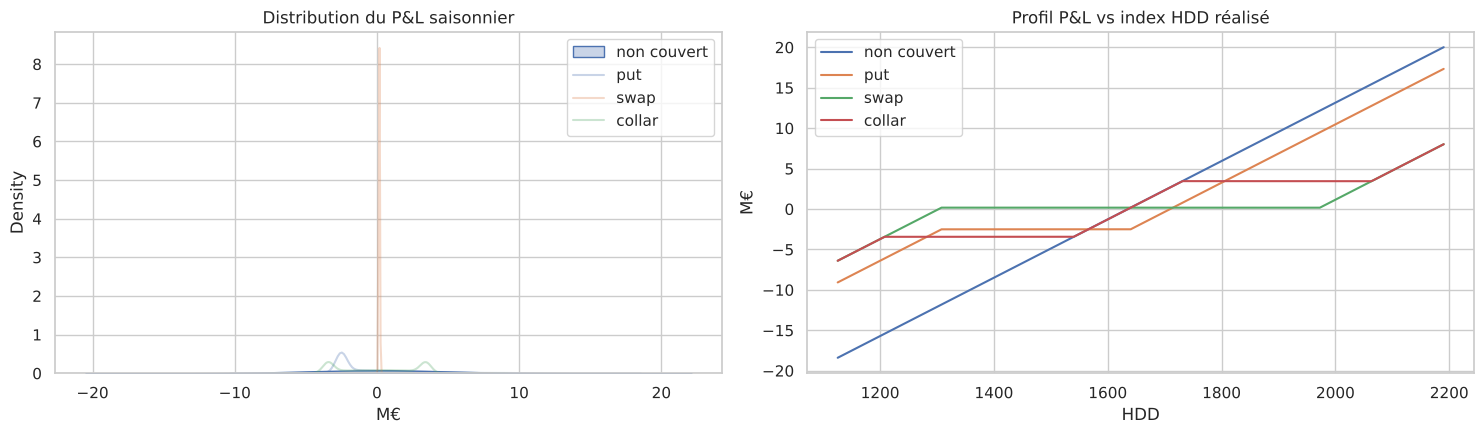

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for x, lab in [(pnl_unhedged, "non couvert"), (pnl_put, "put"), (pnl_swap, "swap"), (pnl_collar, "collar")]:
    sns.kdeplot(x / 1e6, ax=axes[0], label=lab, fill=lab == "non couvert", alpha=0.3)
axes[0].set(title="Distribution du P&L saisonnier", xlabel="M€"); axes[0].legend()

order = np.argsort(I_sim)
for x, lab in [(pnl_unhedged, "non couvert"), (pnl_put, "put"), (pnl_swap, "swap"), (pnl_collar, "collar")]:
    axes[1].plot(I_sim[order], x[order] / 1e6, label=lab)
axes[1].set(title="Profil P&L vs index HDD réalisé", xlabel="HDD", ylabel="M€"); axes[1].legend()
plt.tight_layout(); plt.show()

Tick optimal (min variance, put sans cap) : 52,361 €/HDD vs exposition 36,076
-> un put ne couvre que la moitié basse de la distribution : pour minimiser la variance totale il faut sur-dimensionner le tick. Un swap au tick = exposition couvre tout.


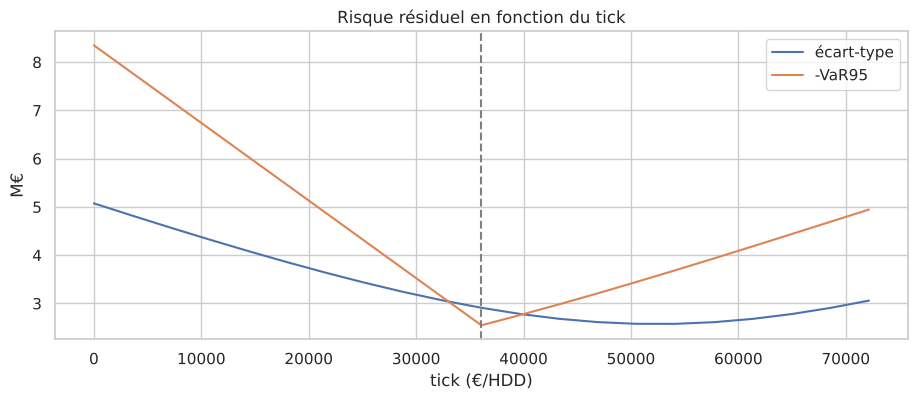

In [36]:
# Dimensionnement : ratio de couverture qui minimise la variance  h* = -Cov(PnL, payoff) / Var(payoff)
unit_put = hedge_put.with_(tick=1.0, cap=np.inf).payoff(I_sim)
h_star = -np.cov(pnl_unhedged, unit_put)[0, 1] / unit_put.var()
print(f"Tick optimal (min variance, put sans cap) : {h_star:,.0f} €/HDD vs exposition {exposure_per_hdd:,.0f}")
print("-> un put ne couvre que la moitié basse de la distribution : pour minimiser la variance totale il faut sur-dimensionner le tick. Un swap au tick = exposition couvre tout.")

ticks = np.linspace(0, 2 * exposure_per_hdd, 21)
stds, vars_ = [], []
unit_prem = mc.price(hedge_put.with_(tick=1.0, cap=np.inf)).ask / mc.discount_factor(hedge_put)
for tk in ticks:
    x = pnl_unhedged + tk * unit_put - tk * unit_prem
    stds.append(x.std()); vars_.append(np.quantile(x, 0.05))
fig, ax = plt.subplots()
ax.plot(ticks, np.array(stds) / 1e6, label="écart-type"); ax.plot(ticks, -np.array(vars_) / 1e6, label="-VaR95")
ax.axvline(exposure_per_hdd, ls="--", color="grey")
ax.set(title="Risque résiduel en fonction du tick", xlabel="tick (€/HDD)", ylabel="M€"); ax.legend(); plt.show()

**Message client (à savoir formuler en 3 phrases) :**
« Votre marge perd environ X € par HDD manquant. Un hiver doux comme 1 an sur 20 vous coûte Y M€. Le put ATM ramène cette perte à Z M€ pour une prime de P k€ ; le collar le fait sans prime, en renonçant au gain au-delà de K_call HDD. »

In [37]:
q05 = risk_tbl.loc["non couvert", "VaR95"]
print(f"Le client perd ~{exposure_per_hdd:,.0f} € par HDD manquant. "
      f"Hiver doux 1-an-sur-20 : {q05/1e6:,.1f} M€. "
      f"Avec le put ATM : {risk_tbl.loc['put ATM','VaR95']/1e6:,.1f} M€ pour {prem_put/1e3:,.0f} k€ de prime. "
      f"Collar 0-coût : {risk_tbl.loc['collar 0-coût','VaR95']/1e6:,.1f} M€, upside abandonné au-delà de {K_call:,.0f} HDD.")

Le client perd ~36,076 € par HDD manquant. Hiver doux 1-an-sur-20 : -8.3 M€. Avec le put ATM : -2.5 M€ pour 2,682 k€ de prime. Collar 0-coût : -3.4 M€, upside abandonné au-delà de 1,731 HDD.


## 9. Suivi de la couverture pendant la période (MtM conditionnel)

En cours de saison, l'index = **partie déjà réalisée** (connue) + **partie restante** (simulée, conditionnée à la dernière température observée grâce à l'AR).
On illustre avec une trajectoire « réalisée » fictive (un scénario du modèle) et on recalcule le MtM du put tous les 15 jours.

In [38]:
model_p = models["Paris"]
realised_path = model_p.simulate(*WINTER, n_sims=1, rng=np.random.default_rng(2024)).iloc[:, 0]
hist_full = pd.concat([T["Paris"], model_p.simulate(T["Paris"].index[-1] + pd.Timedelta(days=1),
                                                    WINTER[0] - pd.Timedelta(days=1), n_sims=1,
                                                    rng=np.random.default_rng(99)).iloc[:, 0]])


def conditional_mtm(contract: WeatherContract, model: TemperatureModel, history: pd.Series,
                    observed: pd.Series, asof: pd.Timestamp, n_sims: int = 10_000, seed: int = 0) -> dict:
    obs = observed.loc[contract.start:asof]
    realised_idx = contract.index_from_temps(obs.to_numpy()[:, None])[0] if len(obs) else 0.0
    hist = pd.concat([history, obs]) if len(obs) else history
    if asof >= contract.end:
        remaining = np.zeros(1)
    else:
        sims = model.simulate(max(asof + pd.Timedelta(days=1), contract.start), contract.end,
                              n_sims=n_sims, rng=np.random.default_rng(seed), history=hist)
        remaining = contract.index_from_temps(sims)
    total = realised_idx + remaining
    pay = contract.payoff(total)
    return {"date": asof, "HDD réalisés": realised_idx, "HDD attendus fin": total.mean(),
            "MtM €": pay.mean(), "P(paiement)": (pay > 0).mean(), "q95 payoff": np.quantile(pay, 0.95)}


asofs = pd.date_range(WINTER[0] - pd.Timedelta(days=1), WINTER[1], freq="15D").append(pd.DatetimeIndex([WINTER[1]]))
track = pd.DataFrame([conditional_mtm(hedge_put, model_p, hist_full, realised_path, d) for d in asofs]).set_index("date")
track

,HDD réalisés,HDD attendus fin,MtM €,P(paiement),q95 payoff
date,,,,,
2026-10-31,0.00,"1,613.88","2,496,899.16",0.57,"9,261,586.63"
2026-11-15,138.81,"1,668.77","1,450,316.29",0.41,"6,899,270.36"
2026-11-30,314.14,"1,689.45","1,066,987.61",0.35,"5,773,290.12"
2026-12-15,591.77,"1,798.35","170,751.08",0.09,"1,220,412.38"
2026-12-30,826.08,"1,861.31","28,066.24",0.02,0.00
2027-01-14,"1,072.34","1,919.65","1,743.73",0.00,0.00
2027-01-29,"1,177.95","1,805.63","28,878.21",0.03,0.00
2027-02-13,"1,345.94","1,790.08","17,965.17",0.02,0.00
2027-02-28,"1,451.02","1,733.30","38,976.70",0.05,"16,648.54"


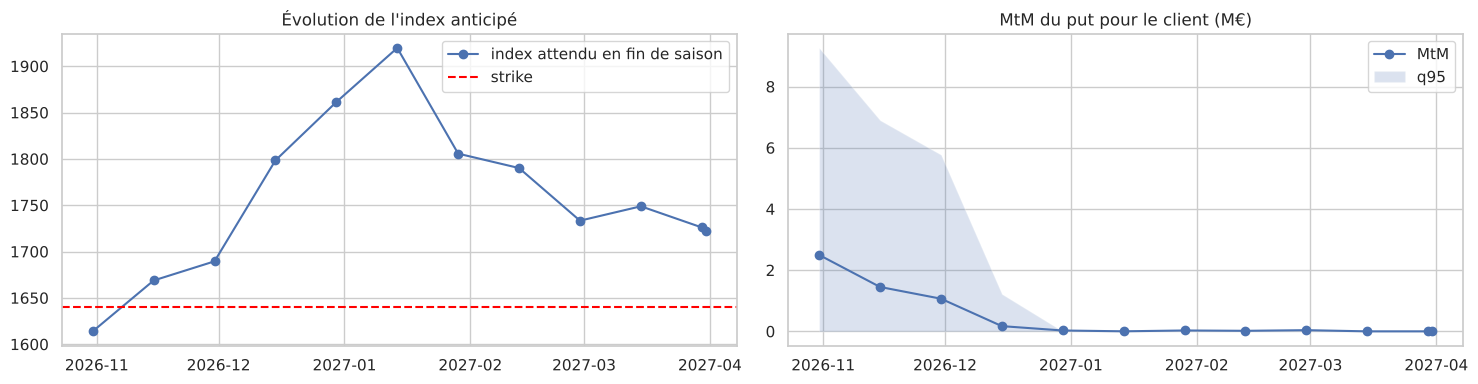

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(track.index, track["HDD attendus fin"], marker="o", label="index attendu en fin de saison")
axes[0].axhline(hedge_put.strike, color="red", ls="--", label="strike")
axes[0].set_title("Évolution de l'index anticipé"); axes[0].legend()
axes[1].plot(track.index, track["MtM €"] / 1e6, marker="o", label="MtM")
axes[1].fill_between(track.index, 0, track["q95 payoff"] / 1e6, alpha=0.2, label="q95")
axes[1].set_title("MtM du put pour le client (M€)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 10. Portefeuille multi-villes et risque de base

Le desk vend un put HDD Paris à un client et le couvre en achetant un put HDD Lyon chez un **capacity provider** (réassureur, hedge fund) — plus liquide ou moins cher.
Le risque résiduel est le **risque de base** : dépend de la corrélation des innovations entre villes. On simule avec des chocs corrélés via **Cholesky**.

In [40]:
innov = pd.concat({c: models[c].std_innov_ for c in CITIES}, axis=1).dropna()
corr = innov.corr().to_numpy()
print("Corrélation des innovations standardisées :\n", np.round(corr, 3))


def correlated_normals(n_days: int, n_sims: int, corr: np.ndarray, rng) -> np.ndarray:
    L = np.linalg.cholesky(corr)
    z = rng.standard_normal((n_days, n_sims, corr.shape[0]))
    return z @ L.T                                    # (jours, sims, villes)


def simulate_joint(models: dict, cities: list[str], start, end, n_sims, corr, seed=0) -> dict[str, pd.DataFrame]:
    rng = np.random.default_rng(seed)
    dates = models[cities[0]].sim_dates(end)
    Z = correlated_normals(len(dates), n_sims, corr, rng)
    return {c: models[c].simulate(start, end, n_sims, rng, z=Z[:, :, j]) for j, c in enumerate(cities)}


joint = simulate_joint(models, list(CITIES), *WINTER, N_SIMS, corr, seed=5)
I_par, I_lyo = (index_from_paths(joint[c], "HDD") for c in CITIES)
print(f"Corrélation des index saisonniers simulés : {np.corrcoef(I_par, I_lyo)[0,1]:.3f}")

Corrélation des innovations standardisées :
 [[1.    0.844]
 [0.844 1.   ]]


Corrélation des index saisonniers simulés : 0.844


In [41]:
sold = hedge_put.with_(name="Short put Paris", position=-1, tick=50_000, cap=np.inf)
# hedge Lyon : même probabilité d'exercice (strike au même quantile), tick ajusté par ratio des écarts-types
q = (I_par < sold.strike).mean()
K_lyo = np.quantile(I_lyo, q)
tick_lyo = sold.tick * I_par.std() / I_lyo.std()
bought = WeatherContract("Long put Lyon", "Lyon", "HDD", "put", strike=round(K_lyo, -1),
                         tick=round(tick_lyo, -2), start=WINTER[0], end=WINTER[1])

pnl_naked = sold.payoff(I_par)
pnl_hedged = pnl_naked + bought.payoff(I_lyo)

# Même hedge si les villes étaient indépendantes (pour illustrer le rôle de la corrélation)
joint0 = simulate_joint(models, list(CITIES), *WINTER, N_SIMS, np.eye(2), seed=5)
pnl_hedged_indep = sold.payoff(index_from_paths(joint0["Paris"])) + bought.payoff(index_from_paths(joint0["Lyon"]))

book = pd.DataFrame([risk_stats(pnl_naked, "short put Paris seul"),
                     risk_stats(pnl_hedged, f"+ long put Lyon (rho={corr[0,1]:.2f})"),
                     risk_stats(pnl_hedged_indep, "+ long put Lyon (rho=0)")]).set_index("stratégie")
print(bought.describe())
book.drop(columns="P(< -1M€)")

Long put HDD Lyon 01/11/2026–31/03/2027, K=1,720, tick=51,500 €/DD, sans cap


,moyenne,écart-type,VaR95,CVaR95
stratégie,,,,
short put Paris seul,"-2,957,548.32","4,202,928.87","-11,880,351.52","-14,753,037.30"
+ long put Lyon (rho=0.84),"14,284.32","2,627,223.68","-4,617,297.66","-6,208,773.56"
+ long put Lyon (rho=0),"-1,987.61","5,970,405.01","-10,359,604.32","-13,310,823.41"


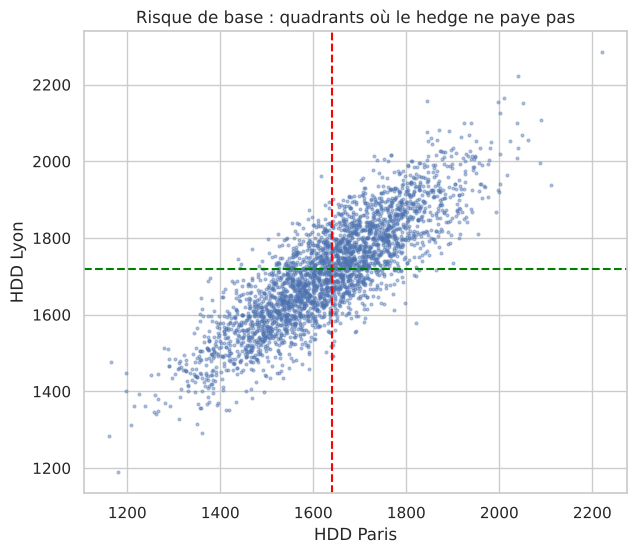

In [42]:
fig, ax = plt.subplots(figsize=(7, 6))
sample = np.random.default_rng(0).choice(N_SIMS, 3000, replace=False)
ax.scatter(I_par[sample], I_lyo[sample], s=4, alpha=0.4)
ax.axvline(sold.strike, color="red", ls="--"); ax.axhline(bought.strike, color="green", ls="--")
ax.set(xlabel="HDD Paris", ylabel="HDD Lyon", title="Risque de base : quadrants où le hedge ne paye pas")
plt.show()

## 11. Tests unitaires

Montrer qu'on teste ses payoffs, c'est un vrai plus. En vrai projet : fichier `tests/test_contracts.py` lancé avec `pytest`.

In [43]:
def test_payoffs():
    c = WeatherContract("t", "Paris", "HDD", "call", strike=100, tick=10, start="2027-01-01", end="2027-01-31", cap=500)
    assert np.allclose(c.payoff([90, 100, 130, 200]), [0, 0, 300, 500])
    p = c.with_(option_type="put")
    assert np.allclose(p.payoff([0, 80, 100, 120]), [500, 200, 0, 0])
    s = c.with_(option_type="swap")
    assert np.allclose(s.payoff([0, 90, 110, 1000]), [-500, -100, 100, 500])
    assert np.allclose(c.with_(position=-1).payoff([130]), [-300])


def test_degree_days():
    t = pd.Series([10.0, 18.0, 25.0], index=pd.date_range("2027-01-01", periods=3))
    d = degree_days(t)
    assert d["HDD"].tolist() == [8, 0, 0] and d["CDD"].tolist() == [0, 0, 7]


def test_seasonal_index_wraps_year():
    idx = pd.date_range("2020-11-01", "2022-03-31")
    s = pd.Series(1.0, index=idx)
    out = seasonal_index(s, (11, 1), (3, 31))
    assert list(out.index) == [2021, 2022]
    assert out.loc[2021] == 151 and out.loc[2022] == 151


def test_put_call_parity_like():
    # long call - long put = swap (sans cap) : C - P = tau (I - K)
    c = WeatherContract("t", "Paris", "HDD", "call", strike=1500, tick=1000, start="2026-11-01", end="2027-03-31")
    I = np.array([1000, 1500, 2000])
    assert np.allclose(c.payoff(I) - c.with_(option_type="put").payoff(I), c.with_(option_type="swap").payoff(I))


def test_invalid_contract():
    try:
        WeatherContract("t", "Paris", "HDD", "call", strike=1, tick=-1, start="2027-01-01", end="2027-02-01")
    except ValueError:
        return
    raise AssertionError("tick négatif accepté")


for f in (test_payoffs, test_degree_days, test_seasonal_index_wraps_year, test_put_call_parity_like, test_invalid_contract):
    f(); print("OK ", f.__name__)

OK  test_payoffs
OK  test_degree_days
OK  test_seasonal_index_wraps_year
OK  test_put_call_parity_like
OK  test_invalid_contract


## 12. Antisèche

### Pandas — séries temporelles
```python
df = pd.read_csv("f.csv", parse_dates=["date"], index_col="date")
df.asfreq("D")                          # calendrier complet (NaN sur les trous)
df.reindex(pd.date_range(a, b, freq="D"))
df.interpolate(method="time", limit=3)
df.resample("MS").mean()                # MS = début de mois, ME = fin de mois, YS, W
df.rolling(30, center=True).mean()
df.groupby(df.index.month).agg(["mean", "std"])
df.groupby([df.index.year, df.index.month])["t"].sum().unstack()
df.loc["2020-11":"2021-03"]             # slicing par date partielle
df.index.dayofyear / .dayofweek / .month / .is_leap_year
df.shift(1), df.diff(), df.pct_change()
pd.merge(a, b, left_index=True, right_index=True, how="inner")
pd.concat({"Paris": s1, "Lyon": s2}, axis=1)
df.pivot_table(index="mois", columns="ville", values="HDD", aggfunc="sum")
df.melt(id_vars="date", var_name="ville", value_name="t")
df.query("t < 0 and mois == 1")
df.assign(HDD=lambda x: (18 - x.t).clip(lower=0))
```

### NumPy
```python
rng = np.random.default_rng(42); rng.standard_normal((n_jours, n_sims))
np.maximum(K - I, 0); np.clip(x, -C, C); np.quantile(x, [0.05, 0.95])
L = np.linalg.cholesky(corr); z_corr = z @ L.T
np.polyfit(x, y, 1)  # pente, ordonnée
x[:, None] * y[None, :]   # broadcasting
```

### POO — gabarit
```python
from abc import ABC, abstractmethod
from dataclasses import dataclass, field

@dataclass(frozen=True)
class Contract:
    strike: float
    tick: float
    def __post_init__(self):
        if self.tick <= 0: raise ValueError("tick > 0")

class Pricer(ABC):
    def price(self, c):                      # template method
        return self.discount(c) * c.payoff(self.index_distribution(c)).mean()
    @abstractmethod
    def index_distribution(self, c): ...

class BurnPricer(Pricer):
    def index_distribution(self, c): ...
```
`@property`, `@classmethod` (constructeur alternatif `from_dict`), `@staticmethod`, `__repr__`, `super().__init__()`, type hints.

### API / requests
```python
r = requests.get(url, params={...}, timeout=30); r.raise_for_status(); js = r.json()
pd.DataFrame(js["daily"]); pd.json_normalize(js, record_path=["items"])
# Session + retries
from requests.adapters import HTTPAdapter; from urllib3.util.retry import Retry
s = requests.Session(); s.mount("https://", HTTPAdapter(max_retries=Retry(total=3, backoff_factor=1)))
```

### statsmodels
```python
sm.OLS(y, sm.add_constant(X)).fit().summary()
AutoReg(resid, lags=1, trend="n").fit().params
ar_select_order(resid, maxlag=10, ic="bic", trend="n").ar_lags
acorr_ljungbox(res, lags=[10], return_df=True)
plot_acf(res, lags=30); plot_pacf(res, lags=30)
```

### Git
```bash
git init; git add .; git commit -m "msg"; git checkout -b feature/x
git log --oneline; git diff; git stash; git merge feature/x; git push -u origin feature/x
```

### Questions d'entretien probables (avec réponse courte)

| Question | Réponse courte |
|---|---|
| Pourquoi pas de Black-Scholes ? | Sous-jacent non échangeable → pas de réplication, marché incomplet. Pricing actuariel (espérance + chargement) ou avec un *market price of risk*. |
| Pourquoi 18°C / 65°F ? | Seuil conventionnel en dessous duquel on chauffe. |
| Biais du burn analysis ? | Tendance non prise en compte (réchauffement → surestime les HDD), petit échantillon (30 pts), queues mal estimées, une seule trajectoire par an. |
| Comment détrender ? | Régression linéaire de l'index sur l'année, ou détrendage des températures journalières puis recalcul. Fenêtre glissante 10–30 ans selon le compromis biais/variance. |
| Pourquoi un AR / OU ? | Persistance des anomalies (vagues de froid). Sans autocorrélation, on sous-estime fortement la variance de l'index saisonnier. |
| Comment tester le modèle ? | ACF/PACF et Ljung-Box sur les innovations, QQ-plot, backtest : distribution simulée vs index historique détrendé, PIT. |
| Risque de base ? | Écart entre l'index couvert (station, ville) et l'exposition réelle du client (volume, autre zone). Mesuré par la corrélation / R² de la régression volume ↔ index. |
| Put vs swap vs collar ? | Put : prime, garde l'upside. Swap : gratuit, symétrique. Collar : réduit/annule la prime en vendant l'upside au-delà d'un seuil. |
| Rôle du cap ? | Limite la perte du vendeur et le capital immobilisé → prix plus bas. |
| Corrélation volume/prix ? | Hiver froid = volumes ET prix spot hauts → risque quanto ; on peut structurer des produits combinés météo × prix. |
| Pourquoi la vol est saisonnière ? | En Europe, l'hiver a des anomalies plus fortes (anticyclones, coulées d'air arctique). |
| Renouvelables ? | Vent / ensoleillement / hydro : indices de production (wind index), même logique de pricing et couverture du volume. |

### Plan de bataille pour les 4h
1. **15 min** : lire l'énoncé en entier, lister les livrables, choisir l'architecture (classes).
2. **45 min** : données (API ou fichier), nettoyage, premiers graphes.
3. **90 min** : cœur du sujet (indices, modèle, pricing) — d'abord une version simple qui marche (burn), puis améliorer (MC).
4. **45 min** : analyse, sensibilités, graphiques, conclusions business.
5. **30 min** : nettoyer le notebook, docstrings, markdown d'explication, relance complète (*Restart & Run All*).